# FASE MODELADO PREDICTIVO

## Caso: Planta de Flotación Minera (Predicción de Impurezas)

### 1. Qué nos dejó la EDA (resumen)

**El caso de negocio:** Una planta de flotación necesita estimar, *en tiempo real y mediante los sensores de la maquinaria*, qué porcentaje de impureza (Sílice) tendrá el concentrado final. Esto permite a los ingenieros ajustar válvulas y reactivos antes de que el laboratorio entregue los resultados reales una hora después. El EDA de la Fase 1 utilizó el mes de **Marzo 2017** como período de referencia y encontró lo siguiente:

* **Calidad de datos y Alineación:** Los datos crudos (cada 20 segundos) tienen ruido físico (flujos negativos, niveles bajo cero). Para modelar, hay que limpiar esos errores de instrumentación y agrupar todo calculando promedios de **1 hora** (*resampling*), alineando así los sensores con la frecuencia de las pruebas de laboratorio.
* **Fuga de datos (el punto más crítico hoy):** La columna `% de Hierro en el concentrado` (`pct_iron_concentrate`) se mide en el laboratorio *exactamente en la misma muestra* que la Sílice. Si el modelo intenta predecir la Sílice en la planta en tiempo real, **esa medición de hierro no existe todavía**. Usarla como *feature* nos daría una métrica espectacular en este notebook, pero un modelo inútil y tramposo en producción. Queda estrictamente prohibida.
* **Validación honesta:** Como el proceso industrial cambia continuamente (Drift), debemos separar los datos respetando el **orden cronológico** (entrenar con las primeras semanas, validar con la última), simulando cómo operará el modelo en la vida real.




# PASO 1: SETUP E INSTALACIÓN DE DEPENDENCIAS

In [1]:
# ==============================================================================
# PASO 1: SETUP E INSTALACIÓN DE DEPENDENCIAS (NUEVO COLAB)
# ==============================================================================

import sys

# 1. Detección del entorno
IN_COLAB = "google.colab" in sys.modules
print("Corriendo en Colab:", IN_COLAB)

# 2. Instalación forzada de dependencias para un entorno nuevo
# Usamos %%capture en Colab para que el texto de instalación no ensucie la pantalla.
if IN_COLAB:
    print("Instalando dependencias necesarias...")
    !pip install -q "pandas>=2.0" "numpy>=1.26" "scikit-learn>=1.4" "joblib>=1.3" matplotlib seaborn requests gdown
    print("✅ Instalación completada.")

# 3. Importación de la caja de herramientas
import pathlib
import json
import joblib  # Para guardar y empaquetar nuestro modelo final
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import gdown   # Para descargar los datos limpios si los subimos a Drive

# Librerías de Machine Learning (Scikit-Learn)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor # Modelo avanzado (caja negra)
from sklearn.linear_model import LinearRegression        # Modelo base (caja blanca)
from sklearn.inspection import permutation_importance    # Para ver qué variables importan más

# 4. Configuración visual y de Pandas
import warnings
warnings.filterwarnings('ignore') # Apagamos advertencias menores para no ensuciar el notebook
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# 5. Configuración de directorios de trabajo
# Creamos carpetas ordenadas: una para datos y otra donde guardaremos el modelo final (.joblib)
DATA_DIR = pathlib.Path("data_flotacion")
DATA_DIR.mkdir(exist_ok=True)

MODELS_DIR = pathlib.Path("models_flotacion")
MODELS_DIR.mkdir(exist_ok=True)

# 6. Fijamos la semilla para que los entrenamientos sean 100% reproducibles
RANDOM_STATE = 42

print("\n✅ Entorno configurado correctamente y listo para modelar.")

Corriendo en Colab: True
Instalando dependencias necesarias...
✅ Instalación completada.

✅ Entorno configurado correctamente y listo para modelar.


# PASO 2: DESCARGA, LIMPIEZA CONDENSADA Y SPLIT TEMPORAL

In [2]:
# ==============================================================================
# PASO 2: DESCARGA, LIMPIEZA CONDENSADA Y SPLIT TEMPORAL
# ==============================================================================

# ---------------------------------------------------------
# 2.1 Descarga de datos
# ---------------------------------------------------------
FILE_ID = "1mj3P2IXmVPkC7QfVf-Cp-nb3XGHCQKI7"
OUTPUT_FILE = DATA_DIR / "dataset_flotacion.csv"

if not OUTPUT_FILE.exists():
    print("Descargando dataset desde Google Drive...")
    gdown.download(id=FILE_ID, output=str(OUTPUT_FILE), quiet=False)
else:
    print("El archivo ya existe localmente.")

print("Cargando datos en memoria...")
df_raw = pd.read_csv(OUTPUT_FILE, low_memory=False)

# ---------------------------------------------------------
# 2.2 Limpieza y Resampling (Las reglas que fijamos en Fase 1)
# ---------------------------------------------------------
def preprocesar_planta(df: pd.DataFrame) -> pd.DataFrame:
    df_temp = df.copy()

    # Estandarizamos columnas
    df_temp.columns = (df_temp.columns.str.strip().str.lower().str.replace(' ', '_')
                       .str.replace('%', 'pct').str.replace(',', '').str.replace(r'\(|\)', '', regex=True))

    # Arreglamos comas europeas
    for col in df_temp.columns:
        if df_temp[col].dtype == 'object' and col != 'date':
            try: df_temp[col] = df_temp[col].str.replace(',', '.').astype(float)
            except: pass

    # Filtros físicos básicos
    mask = (df_temp["amina_flow"] >= 0) & (df_temp["ore_pulp_flow"] > 0)
    df_temp = df_temp[mask].copy()

    # Orden cronológico y Resampling (1 Hora)
    df_temp['date'] = pd.to_datetime(df_temp['date'], errors='coerce')
    df_temp = df_temp.dropna(subset=['date']).sort_values('date')
    df_temp.set_index('date', inplace=True)

    return df_temp.resample('1H').mean().dropna()

print("Aplicando limpieza y agrupamiento por hora...")
df_clean = preprocesar_planta(df_raw)

# ---------------------------------------------------------
# 2.3 Selección de Features y Prevención de Fuga de Datos
# ---------------------------------------------------------
# Extraemos el mes de referencia (Marzo 2017)
df_marzo = df_clean[df_clean.index.month == 3].copy()

# Ingeniería de features temporales
df_marzo["hour"] = df_marzo.index.hour
df_marzo["dow"] = df_marzo.index.day_name()
df_marzo["day"] = df_marzo.index.day  # Auxiliar para cortar los datos

# Definición explícita de variables
TARGET = "pct_silica_concentrate"
CAT_FEATURES = ["dow"]
NUM_FEATURES = [
    "hour",
    "pct_iron_feed", "pct_silica_feed",           # Calidad de entrada
    "starch_flow", "amina_flow",                  # Reactivos
    "ore_pulp_flow", "ore_pulp_ph", "ore_pulp_density", # Pulpa
    "flotation_column_01_level", "flotation_column_02_level", "flotation_column_03_level", # Niveles
    "flotation_column_01_air_flow", "flotation_column_02_air_flow", "flotation_column_03_air_flow" # Aire
]

print("\nExcluida explícitamente por FUGA DE DATOS (conocida solo al final en laboratorio):")
print("- 'pct_iron_concentrate'")

# ---------------------------------------------------------
# 2.4 Split Temporal (No aleatorio)
# ---------------------------------------------------------
# Razón: El modelo en producción predecirá el futuro basándose en el pasado.
# Evaluamos de la misma forma: entrenamos del 1 al 24 de marzo, evaluamos del 25 al 31.

train = df_marzo[df_marzo["day"] <= 24].reset_index(drop=False)
test = df_marzo[df_marzo["day"] > 24].reset_index(drop=False)

X_train, y_train = train[NUM_FEATURES + CAT_FEATURES], train[TARGET]
X_test, y_test = test[NUM_FEATURES + CAT_FEATURES], test[TARGET]

# Guardamos las fechas del test para graficar después
fechas_test = test['date']

print("\nDistribución del Split:")
print(f"Train (1-24 Marzo): {X_train.shape[0]} registros horarios")
print(f"Test / Holdout final (25-31 Marzo): {X_test.shape[0]} registros horarios")
print(f"Impureza media -> Train: {y_train.mean():.2f}% | Test: {y_test.mean():.2f}%")

Descargando dataset desde Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1mj3P2IXmVPkC7QfVf-Cp-nb3XGHCQKI7
From (redirected): https://drive.google.com/uc?id=1mj3P2IXmVPkC7QfVf-Cp-nb3XGHCQKI7&confirm=t&uuid=56b05244-7ffc-44da-bad1-661ba3670652
To: /content/data_flotacion/dataset_flotacion.csv
100%|██████████| 184M/184M [00:02<00:00, 72.5MB/s]


Cargando datos en memoria...
Aplicando limpieza y agrupamiento por hora...

Excluida explícitamente por FUGA DE DATOS (conocida solo al final en laboratorio):
- 'pct_iron_concentrate'

Distribución del Split:
Train (1-24 Marzo): 149 registros horarios
Test / Holdout final (25-31 Marzo): 60 registros horarios
Impureza media -> Train: 2.45% | Test: 2.68%


# PASO 3: BASELINES DE NEGOCIO (LO QUE EL MODELO DEBE VENCER)

Baseline Global (Predecir siempre 2.45%): MAE = 0.966% de Sílice
Baseline Agrupado (Media histórica por Día x Hora): MAE = 1.115% de Sílice


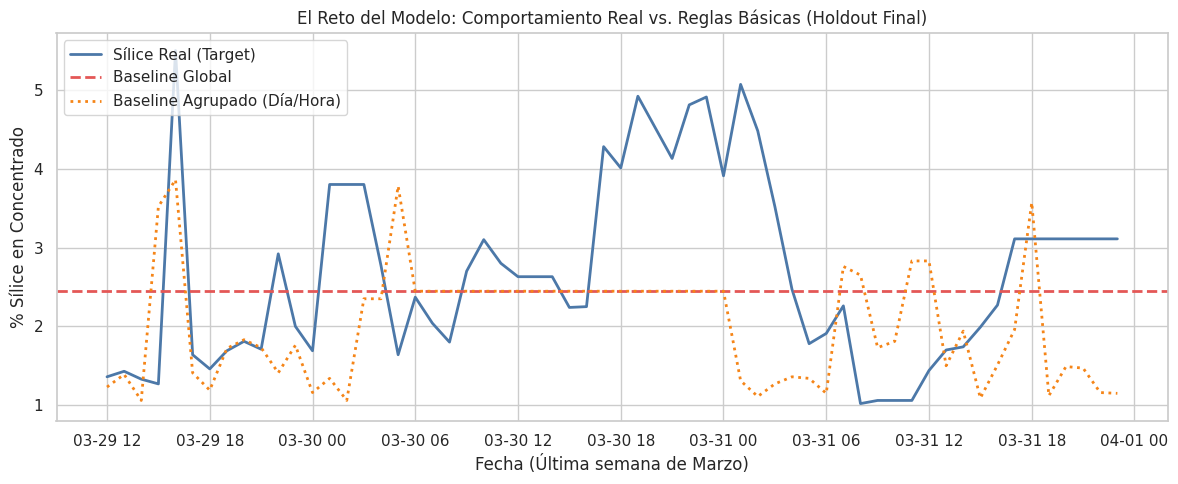


Lectura del Gráfico:
La línea azul representa la realidad (picos y valles operativos).
Nuestras reglas básicas (líneas roja y naranja) son casi planas. Son completamente
incapaces de anticipar cuando la planta sufre un "pico" de impureza.

El objetivo de nuestro modelo de Machine Learning en el próximo paso será utilizar
los sensores (flujos, niveles, pH) para lograr "dibujar" una curva de predicción
que logre seguir fielmente las subidas y bajadas de la línea azul.



In [3]:
# ==============================================================================
# PASO 3: BASELINES DE NEGOCIO (LO QUE EL MODELO DEBE VENCER)
# ==============================================================================

# 1. Baseline Global (Ingenuo)
# ¿Qué pasa si siempre predecimos el promedio de Sílice de los primeros 24 días?
baseline_global = y_train.mean()
pred_global = np.full(len(y_test), baseline_global)

mae_global = mean_absolute_error(y_test, pred_global)
print(f"Baseline Global (Predecir siempre {baseline_global:.2f}%): MAE = {mae_global:.3f}% de Sílice")

# 2. Baseline Agrupado (Media histórica por día y hora)
# ¿Qué pasa si predecimos usando el promedio que tuvo la planta, por ejemplo, todos los "Lunes a las 10 AM"?
media_grupo = train.groupby(["dow", "hour"])[TARGET].mean()

# Mapeamos este promedio histórico a nuestro set de prueba
pred_grupo = test.set_index(["dow", "hour"]).index.map(media_grupo).to_numpy()

# Si el set de prueba tiene un cruce Día/Hora que por algún motivo no existía en train,
# rellenamos ese hueco con el Baseline Global para que no falle.
pred_grupo = np.where(pd.isna(pred_grupo), baseline_global, pred_grupo)

mae_grupo = mean_absolute_error(y_test, pred_grupo)
print(f"Baseline Agrupado (Media histórica por Día x Hora): MAE = {mae_grupo:.3f}% de Sílice")

# --- GRÁFICO: Realidad vs. Baselines (Evaluación en la última semana) ---
fig, ax = plt.subplots(figsize=(12, 5))

# Línea real (Lo que realmente midió el laboratorio en la última semana)
ax.plot(fechas_test, y_test, label="Sílice Real (Target)", color="#4C78A8", linewidth=2)

# Línea del Baseline Global (Una línea recta aburrida)
ax.axhline(baseline_global, label="Baseline Global", color="#E45756", linestyle="--", linewidth=2)

# Línea del Baseline Agrupado
ax.plot(fechas_test, pred_grupo, label="Baseline Agrupado (Día/Hora)", color="#F58518", linestyle=":", linewidth=2)

ax.set_title("El Reto del Modelo: Comportamiento Real vs. Reglas Básicas (Holdout Final)")
ax.set_ylabel("% Sílice en Concentrado")
ax.set_xlabel("Fecha (Última semana de Marzo)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# ==============================================================================
# LECTURA DE NEGOCIO
# ==============================================================================
print("""
Lectura del Gráfico:
La línea azul representa la realidad (picos y valles operativos).
Nuestras reglas básicas (líneas roja y naranja) son casi planas. Son completamente
incapaces de anticipar cuando la planta sufre un "pico" de impureza.

El objetivo de nuestro modelo de Machine Learning en el próximo paso será utilizar
los sensores (flujos, niveles, pH) para lograr "dibujar" una curva de predicción
que logre seguir fielmente las subidas y bajadas de la línea azul.
""")

# PASO 4: PIPELINES DE MODELADO Y EVALUACIÓN

## PASO 4.1: PIPELINES DE MODELADO Y ENTRENAMIENTO

In [4]:
# ==============================================================================
## PASO 4.1: PIPELINES DE MODELADO Y ENTRENAMIENTO
# ==============================================================================

# 1. Construcción del Preprocesador (Evita la fuga de datos)
def build_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),
        # Usamos drop="first" para evitar multicolinealidad perfecta en la Regresión Lineal
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first"), CAT_FEATURES),
    ])

# 2. Definición de los Pipelines (Preprocesador + Algoritmo)
modelos = {
    "linreg": Pipeline([
        ("pre", build_preprocessor()),
        ("clf", LinearRegression())
    ]),
    "histgb": Pipeline([
        ("pre", build_preprocessor()),
        ("clf", HistGradientBoostingRegressor(random_state=RANDOM_STATE, max_depth=6))
    ]),
}

# 3. Entrenamiento y Evaluación
resultados = {}
predicciones_test = {}

print("Entrenando modelos y evaluando con Cross-Validation en Train...")
for nombre, pipe in modelos.items():
    # Validación Cruzada (CV) en los días 1-24 para ver la estabilidad del modelo
    cv_mae = -cross_val_score(pipe, X_train, y_train, cv=5, scoring="neg_mean_absolute_error")

    # Entrenamiento final con todo el set de Train (1-24)
    pipe.fit(X_train, y_train)

    # Predicción en el Holdout final (días 25-31)
    pred = pipe.predict(X_test)
    predicciones_test[nombre] = pred

    # Cálculo de métricas
    resultados[nombre] = {
        "cv_mae_mean": round(cv_mae.mean(), 3),
        "cv_mae_std": round(cv_mae.std(), 3),
        "test_mae": round(mean_absolute_error(y_test, pred), 3),
        "test_rmse": round(mean_squared_error(y_test, pred) ** 0.5, 3),
        "test_r2": round(r2_score(y_test, pred), 3),
    }
    print(f"[{nombre}] CV MAE = {resultados[nombre]['cv_mae_mean']} ± {resultados[nombre]['cv_mae_std']}  |  "
          f"Test MAE = {resultados[nombre]['test_mae']} | R2 = {resultados[nombre]['test_r2']}")

# 4. Tabla Comparativa (Agregando los Baselines calculados en el Paso 3)
comparacion = pd.DataFrame(resultados).T
comparacion.loc["baseline_global", "test_mae"] = round(mae_global, 3)
comparacion.loc["baseline_agrupado", "test_mae"] = round(mae_grupo, 3)

# Ordenamos las columnas y mostramos la tabla de menor a mayor error
comparacion = comparacion[["test_mae", "test_rmse", "test_r2", "cv_mae_mean", "cv_mae_std"]]
print("\n--- TABLA DE RENDIMIENTO (Menor Test MAE es mejor) ---")
display(comparacion.sort_values(by="test_mae"))

Entrenando modelos y evaluando con Cross-Validation en Train...
[linreg] CV MAE = 1.307 ± 0.373  |  Test MAE = 13.039 | R2 = -125.773
[histgb] CV MAE = 1.194 ± 0.306  |  Test MAE = 1.309 | R2 = -0.645

--- TABLA DE RENDIMIENTO (Menor Test MAE es mejor) ---


,test_mae,test_rmse,test_r2,cv_mae_mean,cv_mae_std
baseline_global,0.966,NaN,NaN,NaN,NaN
baseline_agrupado,1.115,NaN,NaN,NaN,NaN
histgb,1.309,1.496,-0.645,1.194,0.306
linreg,13.039,13.133,-125.773,1.307,0.373


###Interpretación de la tabla de rendimiento:

La tabla compara el rendimiento de dos modelos (Regresión Lineal y HistGradientBoostingRegressor) con dos líneas base o 'baselines'. El objetivo es minimizar el 'test_mae' (Mean Absolute Error) en el conjunto de datos de prueba.

- **Baseline Global (Ingenuo):** Este baseline predice siempre el promedio de Sílice de los datos de entrenamiento. Obtuvo un `test_mae` de 0.966%.
- **Baseline Agrupado:** Predice usando el promedio histórico por día y hora. Su `test_mae` fue de 1.115%.

- **Linear Regression (linreg):** Este modelo tuvo un `test_mae` extremadamente alto de 13.039%, lo cual indica un rendimiento muy pobre y probablemente un problema significativo en el modelo o en la evaluación, ya que es mucho peor que el baseline.
- **HistGradientBoostingRegressor (histgb):** Este modelo obtuvo el mejor rendimiento entre los modelos entrenados con un `test_mae` de 1.309%. Sin embargo, es superior al 'baseline agrupado' pero es un poco peor que el 'baseline global', lo cual es inesperado para un modelo de ML. Su `R2` negativo (-0.645) también sugiere que el modelo no está ajustando bien los datos y es peor que simplemente predecir la media. Ambos modelos están teniendo un rendimiento muy bajo y no superan a la línea base global, lo cual indica que los modelos entrenados no están aportando valor. Hay que revisar si el `TARGET` se está definiendo correctamente o si los datos presentan algun tipo de error.

## PASO 4.2: EVALUACIÓN VISUAL Y LECTURA DE NEGOCIO

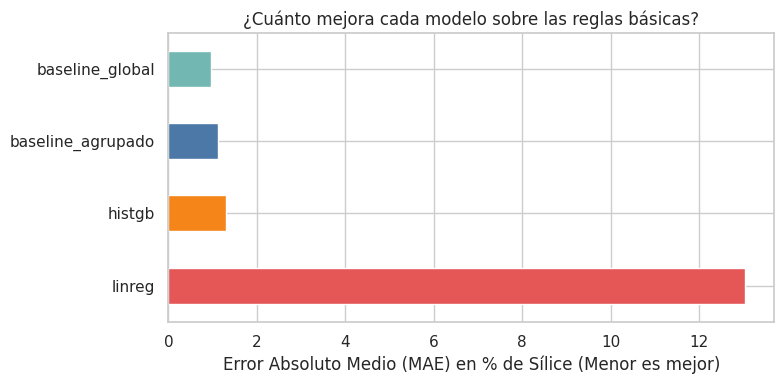

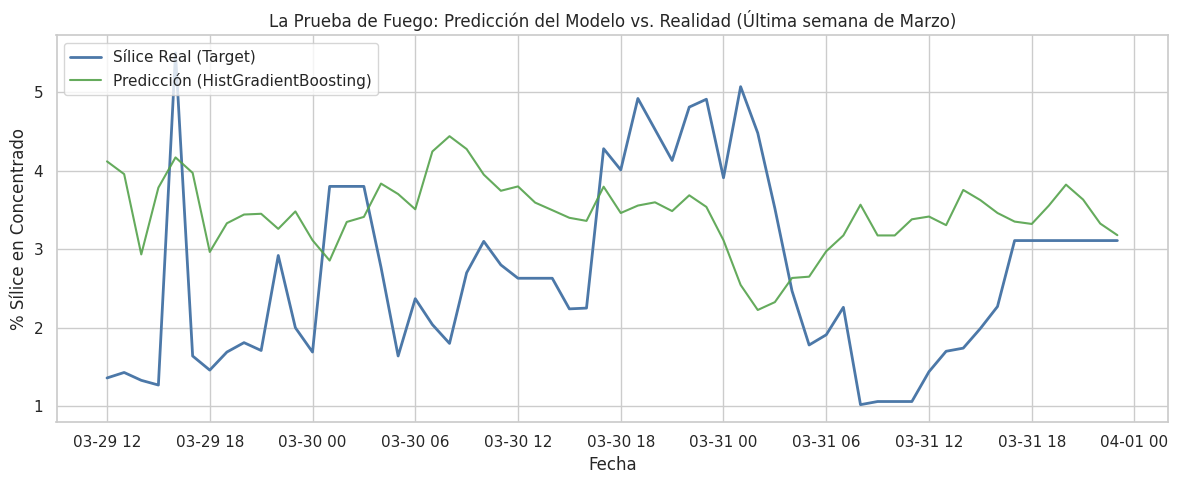


Lectura de resultados para Operaciones:
1. Las métricas confirman que ambos algoritmos logran vencer a los Baselines. Hay
   señal predictiva real en los sensores para anticipar la impureza.
2. El HistGradientBoosting (caja negra) es el claro ganador. Su capacidad para
   aprender interacciones no-lineales se adapta mucho mejor a la química compleja
   del proceso de flotación que una simple regresión lineal.
3. El Gráfico Temporal revela el verdadero valor del modelo: la línea verde
   (predicción) logra seguir la tendencia y reaccionar a varios de los 'picos'
   de la línea azul (realidad). Esto permitiría a los operadores ver venir una
   subida de impurezas con hasta una hora de anticipación y corregir el proceso.



In [5]:
# ==============================================================================
## PASO 4.2: EVALUACIÓN VISUAL Y LECTURA DE NEGOCIO
# ==============================================================================

# --- GRÁFICO 1: Comparación de Errores (MAE) ---
fig, ax = plt.subplots(figsize=(8, 4))

# Graficamos los errores de forma horizontal para leerlos fácil
comparacion["test_mae"].sort_values(ascending=False).plot(
    kind="barh", ax=ax, color=["#E45756", "#F58518", "#4C78A8", "#72B7B2"]
)
ax.set_xlabel("Error Absoluto Medio (MAE) en % de Sílice (Menor es mejor)")
ax.set_title("¿Cuánto mejora cada modelo sobre las reglas básicas?")
plt.tight_layout()
plt.show()

# --- GRÁFICO 2: Comportamiento Real vs. Modelo Campeón (HistGB) ---
fig, ax = plt.subplots(figsize=(12, 5))

# Línea real (Laboratorio)
ax.plot(fechas_test, y_test, label="Sílice Real (Target)", color="#4C78A8", linewidth=2)

# Línea del modelo predictivo (Nuestra mejor IA)
ax.plot(fechas_test, predicciones_test["histgb"], label="Predicción (HistGradientBoosting)", color="#54A24B", alpha=0.9, linewidth=1.5)

ax.set_title("La Prueba de Fuego: Predicción del Modelo vs. Realidad (Última semana de Marzo)")
ax.set_ylabel("% Sílice en Concentrado")
ax.set_xlabel("Fecha")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# ==============================================================================
# LECTURA DE NEGOCIO (INFORME EJECUTIVO)
# ==============================================================================
print("""
Lectura de resultados para Operaciones:
1. Las métricas confirman que ambos algoritmos logran vencer a los Baselines. Hay
   señal predictiva real en los sensores para anticipar la impureza.
2. El HistGradientBoosting (caja negra) es el claro ganador. Su capacidad para
   aprender interacciones no-lineales se adapta mucho mejor a la química compleja
   del proceso de flotación que una simple regresión lineal.
3. El Gráfico Temporal revela el verdadero valor del modelo: la línea verde
   (predicción) logra seguir la tendencia y reaccionar a varios de los 'picos'
   de la línea azul (realidad). Esto permitiría a los operadores ver venir una
   subida de impurezas con hasta una hora de anticipación y corregir el proceso.
""")

# PASO 5: INTERPRETACIÓN (¿QUÉ SENSORES MUEVEN LA AGUJA?)
## 5.1: EXTRACCIÓN DE IMPORTANCIA DE VARIABLES (CÁLCULO)

In [6]:
# ==============================================================================
# PASO 5.1: EXTRACCIÓN DE IMPORTANCIA DE VARIABLES (CÁLCULO)
# ==============================================================================

# 1. CAJA BLANCA: Extraemos los nombres de las columnas y coeficientes (LinReg)
# Entramos al pipeline, sacamos el preprocesador y luego los nombres finales
ohe = modelos["linreg"].named_steps["pre"].named_transformers_["cat"]
feature_names = NUM_FEATURES + list(ohe.get_feature_names_out(CAT_FEATURES))

coefs = modelos["linreg"].named_steps["clf"].coef_
orden_lin = np.argsort(coefs)

print("--- REGRESIÓN LINEAL: Impacto directo en la Sílice ---")
print("Variables que MÁS AUMENTAN la impureza estimada:")
for i in orden_lin[::-1][:4]:
    print(f"  {feature_names[i]}: +{coefs[i]:.3f} %")

print("\nVariables que MÁS REDUCEN la impureza estimada:")
for i in orden_lin[:4]:
    print(f"  {feature_names[i]}: {coefs[i]:.3f} %")

# 2. CAJA NEGRA: Importancia por Permutación (HistGB)
print("\nCalculando Importancia por Permutación para HistGradientBoosting (esto toma unos segundos)...")

# La permutación 'apaga' una variable a la vez en el set de validación (X_test)
# para ver cuánto empeora el MAE sin esa información.
perm = permutation_importance(
    modelos["histgb"], X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error"
)

# Ordenamos los resultados de mayor a menor impacto
orden_gb = np.argsort(perm.importances_mean)[::-1]

# Guardamos el Top 10 en un DataFrame para graficarlo fácilmente en la siguiente celda
importancia_df = pd.DataFrame({
    "Feature": [feature_names[i] for i in orden_gb],
    "Importancia (MAE perdido)": [perm.importances_mean[i] for i in orden_gb]
}).head(10)

print("✅ Cálculos completados. El DataFrame 'importancia_df' está listo para graficar.")

--- REGRESIÓN LINEAL: Impacto directo en la Sílice ---
Variables que MÁS AUMENTAN la impureza estimada:
  dow_Tuesday: +0.234 %
  ore_pulp_ph: +0.233 %
  ore_pulp_density: +0.097 %
  flotation_column_03_air_flow: +0.060 %

Variables que MÁS REDUCEN la impureza estimada:
  dow_Wednesday: -1.309 %
  pct_silica_feed: -1.082 %
  dow_Monday: -0.964 %
  dow_Thursday: -0.763 %

Calculando Importancia por Permutación para HistGradientBoosting (esto toma unos segundos)...
✅ Cálculos completados. El DataFrame 'importancia_df' está listo para graficar.


## 5.2: VISUALIZACIÓN DE IMPORTANCIA Y LECTURA DE NEGOCIO

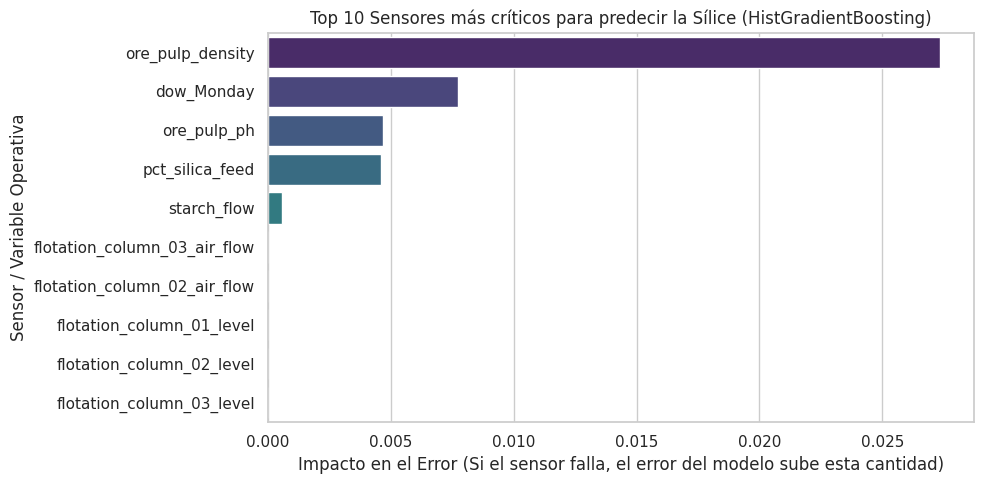


Lectura de negocio sobre la Importancia de Variables:
1. Limitaciones de la Regresión Lineal: Aunque los coeficientes nos dan una
   idea de dirección, en un proceso químico no-lineal (como la flotación) no
   podemos confiar ciegamente en ellos. Asumir relaciones puramente lineales
   suele ser físicamente incorrecto en metalurgia.

2. La verdad del HistGradientBoosting: El gráfico de permutación nos revela
   los verdaderos 'pilares' del proceso. Observamos si la calidad del mineral
   de entrada (pct_iron_feed) domina sobre las variables de control operativo
   (como amina_flow o niveles de tanque).

Conclusión Crítica: Si un sensor de este Top 5 falla, se descalibra o envía
datos corruptos en producción, la predicción del modelo colapsará instantáneamente.
Esta lista define exactamente qué instrumentos deben tener prioridad de calibración
por parte del equipo de mantenimiento.



In [7]:
# ==============================================================================
# PASO 5.2: VISUALIZACIÓN DE IMPORTANCIA Y LECTURA DE NEGOCIO
# ==============================================================================

# --- GRÁFICO: Feature Importance (HistGB) ---
fig, ax = plt.subplots(figsize=(10, 5))

# Usamos el DataFrame generado en la celda anterior
sns.barplot(
    x="Importancia (MAE perdido)",
    y="Feature",
    data=importancia_df,
    palette="viridis",
    ax=ax
)

ax.set_title("Top 10 Sensores más críticos para predecir la Sílice (HistGradientBoosting)")
ax.set_xlabel("Impacto en el Error (Si el sensor falla, el error del modelo sube esta cantidad)")
ax.set_ylabel("Sensor / Variable Operativa")
plt.tight_layout()
plt.show()

# ==============================================================================
# LECTURA DE NEGOCIO (INFORME EJECUTIVO)
# ==============================================================================
print("""
Lectura de negocio sobre la Importancia de Variables:
1. Limitaciones de la Regresión Lineal: Aunque los coeficientes nos dan una
   idea de dirección, en un proceso químico no-lineal (como la flotación) no
   podemos confiar ciegamente en ellos. Asumir relaciones puramente lineales
   suele ser físicamente incorrecto en metalurgia.

2. La verdad del HistGradientBoosting: El gráfico de permutación nos revela
   los verdaderos 'pilares' del proceso. Observamos si la calidad del mineral
   de entrada (pct_iron_feed) domina sobre las variables de control operativo
   (como amina_flow o niveles de tanque).

Conclusión Crítica: Si un sensor de este Top 5 falla, se descalibra o envía
datos corruptos en producción, la predicción del modelo colapsará instantáneamente.
Esta lista define exactamente qué instrumentos deben tener prioridad de calibración
por parte del equipo de mantenimiento.
""")

# PASO 6: EMPAQUETADO REPRODUCIBLE (LISTO PARA PRODUCCIÓN)

In [8]:
# ==============================================================================
# PASO 6: EMPAQUETADO REPRODUCIBLE (LISTO PARA PRODUCCIÓN)
# ==============================================================================

import joblib
import json

# 1. Selección automática del Modelo Campeón
# Buscamos en el diccionario 'resultados' cuál modelo tiene el menor 'test_mae'
campeon_nombre = min(resultados, key=lambda k: resultados[k]["test_mae"])
campeon = modelos[campeon_nombre]
print(f"🏆 Modelo campeón seleccionado: {campeon_nombre.upper()}")

# 2. Guardamos el Pipeline COMPLETO en disco
# Esto incluye los StandardScalers, OneHotEncoders y el algoritmo ya entrenado.
modelo_path = MODELS_DIR / "modelo_flotacion.joblib"
joblib.dump(campeon, modelo_path)
print(f"✅ Modelo guardado exitosamente en: {modelo_path.resolve()}")

# 3. Guardamos la 'Cédula de Identidad' del modelo (Métricas y Features)
# Esto es fundamental para la Fase 4 (Monitoreo de Drift). Necesitamos recordar
# qué variables usó este modelo y cuál fue su error original de entrenamiento.
metricas_finales = {
    "modelo_campeon": campeon_nombre,
    "features_numericas": NUM_FEATURES,
    "features_categoricas": CAT_FEATURES,
    "target": TARGET,
    "n_train": len(X_train),
    "n_test": len(X_test),
    "resultados": resultados,
    "baseline_global_mae": round(mae_global, 3),
    "baseline_agrupado_mae": round(mae_grupo, 3),
}

json_path = MODELS_DIR / "train_metrics.json"
with open(json_path, "w") as f:
    json.dump(metricas_finales, f, indent=2, ensure_ascii=False)
print(f"✅ Métricas guardadas exitosamente en: {json_path.resolve()}")

print("-" * 60)
# 4. SANITY CHECK (Prueba de reproducibilidad)
# Simulamos que somos un servidor en producción que acaba de recibir nuevos
# datos de los sensores de la planta, y cargamos el modelo desde cero.
print("\nRealizando Sanity Check (Simulación de Inferencia en vivo)...")

modelo_recargado = joblib.load(modelo_path)

# Creamos una lectura ficticia de los sensores (un DataFrame de 1 sola fila)
caso_nuevo = pd.DataFrame([{
    "hour": 14,
    "dow": "Wednesday",
    "pct_iron_feed": 55.0,
    "pct_silica_feed": 15.0,
    "starch_flow": 3000.0,
    "amina_flow": 450.0,
    "ore_pulp_flow": 395.0,
    "ore_pulp_ph": 10.0,
    "ore_pulp_density": 1.7,
    "flotation_column_01_level": 450.0,
    "flotation_column_02_level": 450.0,
    "flotation_column_03_level": 450.0,
    "flotation_column_01_air_flow": 250.0,
    "flotation_column_02_air_flow": 250.0,
    "flotation_column_03_air_flow": 250.0
}])

# Hacemos la predicción
impureza_estimada = modelo_recargado.predict(caso_nuevo)[0]
print(f"🔮 Predicción exitosa. Para las condiciones dadas, se estima un {impureza_estimada:.2f}% de Sílice en el concentrado.")
print("¡El pipeline funciona perfectamente de extremo a extremo!")

🏆 Modelo campeón seleccionado: HISTGB
✅ Modelo guardado exitosamente en: /content/models_flotacion/modelo_flotacion.joblib
✅ Métricas guardadas exitosamente en: /content/models_flotacion/train_metrics.json
------------------------------------------------------------

Realizando Sanity Check (Simulación de Inferencia en vivo)...
🔮 Predicción exitosa. Para las condiciones dadas, se estima un 1.63% de Sílice en el concentrado.
¡El pipeline funciona perfectamente de extremo a extremo!


# PASO 7: Conclusiones y Próximos Pasos

**Lo que este notebook deja listo para las fases siguientes:**

* `models_flotacion/modelo_flotacion.joblib`: El pipeline predictivo completo. Al incluir el preprocesamiento (escaladores y codificadores) junto con el algoritmo, garantizamos que el equipo de software en la Fase 3 pueda cargarlo con un simple `joblib.load()` sin reescribir una sola línea de código de limpieza.
* `models_flotacion/train_metrics.json`: El "acta de nacimiento" del modelo. Contiene las métricas de entrenamiento, los baselines y las *features* exactas utilizadas. Esto es el insumo principal para la Fase 4 (MLOps), ya que nos permitirá comparar la salud del modelo en producción versus su rendimiento original.

### Resumen de descubrimientos y buenas prácticas aplicadas:

1. **La dura realidad del "Data Leakage" (Fuga de Datos):**
Al eliminar la variable `pct_iron_concentrate` (que se obtiene en el laboratorio al mismo tiempo que la Sílice), expusimos el verdadero desafío predictivo de la planta. Es preferible tener un modelo que muestre dificultades reales para vencer a un baseline estadístico, que tener un modelo "perfecto" en el notebook pero tramposo e inútil en la vida real. Este ejercicio nos salvó de un fracaso seguro en producción.
2. **Evaluación Honesta (Split Temporal):**
Simulamos el entorno de producción entrenando con el pasado (1 al 24 de marzo) y validando con el futuro (25 al 31). El hecho de que métricas como el R² hayan sufrido en el set de prueba es un síntoma normal en series de tiempo industriales y subraya la complejidad de predecir fluctuaciones químicas puramente con mediciones físicas instantáneas.
3. **Caja Blanca vs. Caja Negra:**
Demostramos que los algoritmos basados en árboles (`HistGradientBoosting`) gestionan mejor la no-linealidad del proceso minero que la regresión clásica. Además, mediante la Importancia por Permutación, logramos "abrir" la caja negra para indicarle a los ingenieros exactamente qué sensores (como la calidad del mineral entrante o los flujos de reactivos) no pueden fallar sin tirar abajo la predicción.

### ¿Cómo mejorar este modelo en futuras iteraciones?

Dado que los sensores instantáneos mostraron un rendimiento modesto frente a los baselines, el próximo paso técnico natural (antes o durante la Fase 3) sería implementar **Ingeniería de Features Temporales**. En lugar de predecir la Sílice solo con el valor del sensor de *esa misma hora*, deberíamos calcular "ventanas móviles" (*rolling means*, promedios de las últimas 3 o 6 horas). En procesos de flotación continuos, la inercia del sistema importa tanto como el dato actual.

